# Practice Session PS05: Content-based recommendation

Author: <font color="#2680EB">Roger Trilla Piniés</font>

E-mail: <font color="#2680EB">roger.trilla01@estudiant.upf.edu</font>

AI used: <font color="#2680EB">Google, Gemini.</font>

Date: <font color="#2680EB">28/10/2026</font>

In [1]:
# LEAVE AS-IS

# Required libraries
import pandas as pd   
import numpy as np  
import re
import random

# Plotting libraries
import seaborn as sns
import matplotlib.pyplot as plt 

# Sci-kit specific libraries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [3]:
# LEAVE AS-IS

FILENAME_MOVIES = "movies.csv.gz"

In [4]:
# LEAVE AS-IS

# Load movies
movies = pd.read_csv(FILENAME_MOVIES, 
                    compression='gzip',
                    sep="\t", 
                    engine='python', 
                    encoding='utf-8')

# Display a random sample
print(f"Loaded {len(movies)} movies, here is a sample:")
display(movies.sample(3))

Loaded 9751 movies, here is a sample:


,id,title,overview,tags,genres,director,actors,characters,year,votes,rating,popularity,budget,poster_url
8143,13812,Quarantine,A television reporter and her cameraman are tr...,"zombies,""""""found footage"""""",found footage,isol...","drama,horror,mystery",John Erick Dowdle,"Joey King,Doug Jones,Johnathon Schaech,Marin H...","Briana,Thin Infected Man,George Fletcher,Kathy...",2008,1070,5.766,13.161,12000000,https://image.tmdb.org/t/p/w154/rGfOD8IC1x4Pqm...
5741,46261,Don't Be Afraid of the Dark,A young girl sent to live with her father and ...,"cheesy,guillermo del toro,remake,folklore,mons...","horror,thriller",Troy Nixey,"Bailee Madison,Guy Pearce,Katie Holmes,Alan Da...","Sally Hirst,Alex Hirst,Kim,Jacoby,Librarian,Ha...",2010,908,5.728,16.966,25000000,https://image.tmdb.org/t/p/w154/pGVVei8KbztCiu...
4352,296098,Bridge of Spies,"During the Cold War, the Soviet Union captures...","cold war,spy,tom hanks,historical,political th...","drama,thriller",Steven Spielberg,"Tom Hanks,Jesse Plemons,Noah Schnapp,Mark Ryla...","James B. Donovan,Joe Murphy,Roger Donovan,Rudo...",2015,6088,7.226,20.839,40000000,https://image.tmdb.org/t/p/w154/bORlvwnVJE1Z6y...


# 1. Create a function to find movies <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement find_movies** to find movies containing a keyword.</font>

In [7]:
def find_movies(keyword, movies):
    # Busquem les pel·lícules per la paraula clau
    result = movies[movies['title'].str.contains(keyword, case=False, na=False)]
    for _, row in result.iterrows():
        print(f"id: {row['id']:6d}, title: {row['title']}")

find_movies("Purple", movies)

id: 762975, title: Purple Hearts
id:    873, title: The Color Purple


# 2. Distributions of genre and keywords

In [8]:
# LEAVE AS-IS

def print_genres(df):
    print(f"Movies         : {len(df)}" )
    print(f" Without genre : {df['genres'].isna().sum()}" )
    print(f" With genre    : {df['genres'].notna().sum()}" )
    print()

    
    all_genres = set()
    for s in df['genres'].dropna().str.split(',').values:
        all_genres = all_genres.union(set(s))
    print(all_genres)
    
print_genres(movies)
    

Movies         : 9751
 Without genre : 50
 With genre    : 9701

{'imax', 'History', 'fantasy', 'Romance', 'TV Movie', 'Family', 'thriller', 'Adventure', 'war', 'comedy', '(no genres listed)', 'horror', 'sci-fi', 'documentary', 'Horror', 'Fantasy', 'film-noir', 'Documentary', 'Western', 'adventure', 'romance', 'Mystery', 'Drama', 'Action', 'action', 'Comedy', 'Crime', 'Animation', 'War', 'Science Fiction', 'Music', 'musical', 'drama', 'western', 'Thriller', 'children', 'mystery', 'crime', 'animation'}


## 2.1. Prepare the "genre" column <font color="#2680EB">[15%]</font>

<font size="+1" color="#2680EB">**Indicate what problems do you see in the genre column, and how would you clean this column.**</font>

**Responses.**

**What issues do you see in the list of genres below?**

* Veig que hi ha gèneres que són exactament el mateix. Per citar un exemple, sci-fi i Science Fiction. També hi ha un gènere que és (no genres listed), això no ens dona cap gènere. Per últim, veig que hi ha paraules en majúscula, minúscula, amb espais i sense, no hi ha consistència.

**How would you clean this column?**

* El primer seria unificar els gèneres que són sinònims. Canviaria també el (no genres listed) per valors nuls i eliminaria espais innecesaris apart d'estandaritzar la forma en la que estan escrites les paraules.


<font size="+1" color="#2680EB">**Clean the genre column**. In particular, make sure "(no genres listed)" is NULL, and that there are no (near)duplicate genres.</font>

In [14]:
movies1 = movies.copy()

# Estableixo el (no genres listed) a NULL
movies1['genres'] = movies1['genres'].replace('(no genres listed)', np.nan)

# Netejo els espais i trec els duplicats
def clean_genres(val):
    if pd.isna(val):
        return np.nan
    genres = [g.strip().lower() for g in val.split(',')]
    unique_genres = list(dict.fromkeys(genres))
    return ','.join(unique_genres)

movies1['genres'] = movies1['genres'].apply(clean_genres)

print_genres(movies1)

Movies         : 9751
 Without genre : 100
 With genre    : 9651

{'imax', 'fantasy', 'action', 'thriller', 'science fiction', 'history', 'war', 'comedy', 'horror', 'sci-fi', 'musical', 'drama', 'documentary', 'animation', 'music', 'film-noir', 'tv movie', 'western', 'adventure', 'mystery', 'children', 'romance', 'crime', 'family'}


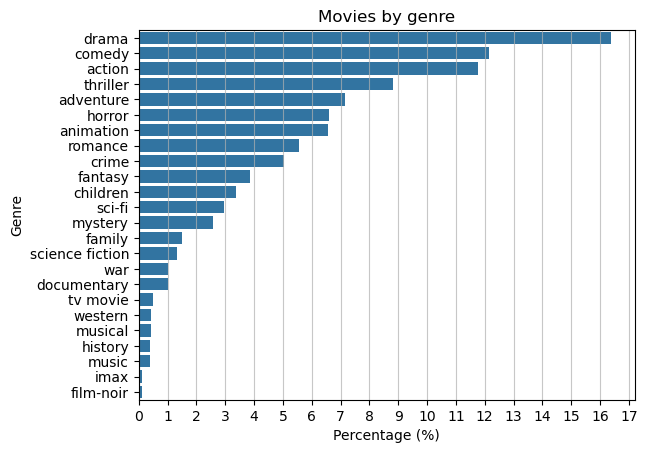

In [15]:
# LEAVE AS-IS

def plot_genres(df):
    
    # Convert genres into a list (i.e., "explode" it)
    exploded_genres = df['genres'].str.split(',').explode().str.strip()

    # Create frequency DataFrame
    genre_counts = exploded_genres.value_counts().reset_index()
    genre_counts.columns = ['genre', 'count']
    genre_counts['percent'] = (genre_counts['count'] / genre_counts['count'].sum()) * 100

    # Create barchart
    sns.barplot(data=genre_counts, x='percent', y='genre', legend=False)
    plt.title('Movies by genre')
    plt.xlabel('Percentage (%)')
    plt.ylabel('Genre')
    
    # Add vertical lines
    # The instructor used AI to set this grid (Gemini 3.6 Flash)
    max_percentage = int(np.ceil(genre_counts['percent'].max()))
    plt.xticks(np.arange(0, max_percentage + 1, 1 ))
    plt.grid(axis='x', alpha=0.7)
    
    plt.show()

plot_genres(movies1)

<font size="+1" color="#2680EB">**Merge genres** using the specification above.</font>

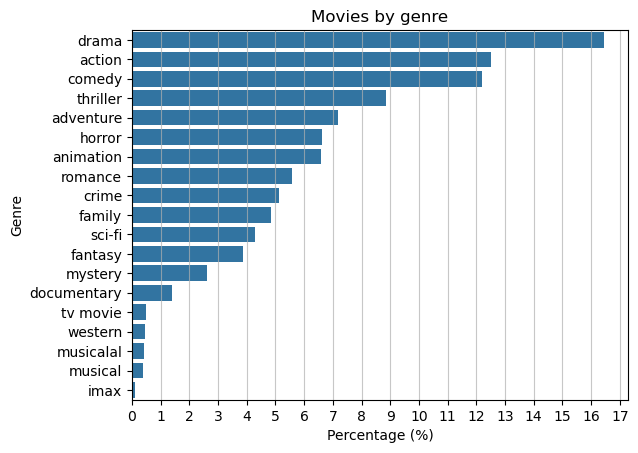

In [16]:
#AI, jo no havia pensat en que s'havien d'eliminar els possibles duplicats que podia tenir al canviar les parelles. El Gemini m'ho ha recordat ja que em sortia un error

pairs_to_replace = [
    ('film-noir', 'crime'),
    ('music', 'musical'),
    ('science fiction', 'sci-fi'),
    ('history', 'documentary'),
    ('children', 'family'),
    ('war', 'action')
]

movies2 = movies1.copy()

# Canviem els gèneres anteriors pels nous
for old, new in pairs_to_replace:
    movies2['genres'] = movies2['genres'].str.replace(old, new, regex=False)

# Eliminem els possibles duplicats al barrejar
movies2['genres'] = movies2['genres'].apply(clean_genres)

plot_genres(movies2)

## 2.2. Merge genres and tags into keywords <font color="#2680EB">[15%]</font>

<font size="+1" color="#2680EB">**Create column "keywords".** It should contain a list, which should be the union of "genres" and "tags".</font>

In [19]:
# Merge source1 and source2 (comma-separated) into target (list)
def merge_csv_arrays(df, source1, source2, target):
    
    # Copy the dataframe
    dfc = df.copy()
    
    # Passo a minúscula i trec els espais
    def extract_list(val):
        if pd.isna(val):
            return []
        if isinstance(val, list):
            return val
        return [item.strip().lower() for item in str(val).split(',') if item.strip()]

    #Combino gèneres i tags en una sola llista
    def combine_sources(row):
        list1 = extract_list(row[source1])
        list2 = extract_list(row[source2])
        return list(dict.fromkeys(list1 + list2))

    dfc[target] = dfc.apply(combine_sources, axis=1)
    
    # Replaces missing values with an empty list
    dfc[target] = dfc[target].mask(dfc[target].isna(), [[] for _ in range(len(dfc))])
    return dfc

movies3 = merge_csv_arrays(movies2, "genres", "tags", "keywords")

In [20]:
# LEAVE AS-IS

# Sample 3 random movies
for i in range(3):
    movie = movies3[['title', 'genres', 'tags', 'keywords']].sample().iloc[0]

    # Print genres, tags → keywords
    print(f"Title: {movie['title']}")
    print(f" genres={movie['genres']}, tags={movie['tags']} => keywords={movie['keywords']}")
    print()


Title: Farewell Song
 genres=romance,drama, tags=nan => keywords=['romance', 'drama']

Title: Her Infidelity
 genres=thriller, tags=nan => keywords=['thriller']

Title: Rise of the Planet of the Apes
 genres=action,drama,sci-fi, tags=genetics,thought-provoking,sci-fi,action,special effects,computer animation,virus,cgi,touching,apes => keywords=['action', 'drama', 'sci-fi', 'genetics', 'thought-provoking', 'special effects', 'computer animation', 'virus', 'cgi', 'touching', 'apes']



# 3. Content-based recommendation

## 3.1. Compute TF-IDF vectors

In [21]:
# LEAVE AS-IS

tfidf = TfidfVectorizer(analyzer=lambda x: x, min_df=1)
tfidf_matrix = tfidf.fit_transform(movies3['keywords'])
print(f"The TF-IDF matrix has {tfidf_matrix.shape[0]} rows (movies)")
print(f"The TF-IDF matrix has {tfidf_matrix.shape[1]} columns (distinct keywords)")

The TF-IDF matrix has 9751 rows (movies)
The TF-IDF matrix has 7876 columns (distinct keywords)


## 3.2. Calculate most similar movies <font color="#2680EB">[20%]</font>

In [22]:
# LEAVE AS-IS

cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

print(f"The similarity matrix has {cosine_sim.shape[0]} rows and {cosine_sim.shape[1]} columns")
print(cosine_sim)

The similarity matrix has 9751 rows and 9751 columns
[[1.         0.         0.62458116 ... 0.63207312 0.         0.        ]
 [0.         1.         0.         ... 0.         0.         0.        ]
 [0.62458116 0.         1.         ... 0.20997285 0.35270144 0.        ]
 ...
 [0.63207312 0.         0.20997285 ... 1.         0.         0.        ]
 [0.         0.         0.35270144 ... 0.         1.         0.43488846]
 [0.         0.         0.         ... 0.         0.43488846 1.        ]]


<font size="+1" color="#2680EB">**Create functions "get_title", "get_index_by_movieid",  "get_movieid_by_index".** They should, respectively, return the title, the index of the row of a movie with id=movieid, and the movieid of the row of a movie indexed by index. In all cases, make sure they return a null ("None") if this is not found.</font>

In [25]:
def get_title_by_movieid(df, movie_id):
    # Busco el títol de la pel·lícula pel seu id
    res = df[df['id'] == movie_id]['title']
    return res.values[0] if len(res) > 0 else None

def get_index_by_movieid(df, movie_id):
    # Busco l'índex de la fila
    res = df[df['id'] == movie_id]
    return res.index[0] if len(res) > 0 else None

def get_movieid_by_index(df, idx):
    # Retorno el movie_id
    if idx in df.index:
        return df.loc[idx, 'id']
    return None

In [24]:
# LEAVE AS-IS

# Test with a random sample
for i in range(5):
    movie_id = movies3.sample()['id'].iloc[0]
    print(f"Movie id    : {movie_id}")
    print(f"Title       : {get_title_by_movieid(movies3, movie_id)}")
    idx = get_index_by_movieid(movies3,movie_id)
    print(f"Movie index : {idx}" )
    movie_id_recovered = get_movieid_by_index(movies3,idx)
    print(f"Check id    : {movie_id_recovered}")
    
    assert movie_id_recovered == movie_id
    print()

Movie id    : 14207
Title       : The Librarian: Quest for the Spear
Movie index : 7614
Check id    : 14207

Movie id    : 603119
Title       : The Silencing
Movie index : 3504
Check id    : 603119

Movie id    : 449756
Title       : The Postcard Killings
Movie index : 6716
Check id    : 449756

Movie id    : 13374
Title       : Ice Princess
Movie index : 8058
Check id    : 13374

Movie id    : 9952
Title       : Rescue Dawn
Movie index : 9669
Check id    : 9952



<font size="+1" color="#2680EB">**Implement "get_similarities_for_movieid".** It should obtain the corresponding row in a similarity matrix, and return a dictionary where keys are movie ids and values are similarities.</font>

In [27]:
# Return all similarities to a given movie
def get_similarities_for_movieid(df, similarities, source_id):
    source_idx = get_index_by_movieid(df, source_id)
    if source_idx is None:
        return {}
    sim_row = similarities[source_idx]
    output = {}
    
    # Recorro les similituds i faig un diccionari
    for idx, sim in enumerate(sim_row):
        m_id = get_movieid_by_index(df, idx)
        if m_id is not None:
            output[m_id] = sim
            
    return output

In [28]:
# LEAVE AS-IS
    
# Test your function
test_movie_id = 4256
print(f"Test movie_id {test_movie_id}, title '{movies3[movies3['id']==test_movie_id]['title'].values[0]}'")

# Call your function
sim_dictionary = get_similarities_for_movieid(movies3, cosine_sim, 4256)

# Samples some key, value pairs from the result
sample_size = 10
sim_dictionary_sample = dict(random.sample(list(sim_dictionary.items()), sample_size))

# Prints those
for other_movie_id, sim in sim_dictionary_sample.items():
    other_movie_title = movies3[movies3['id']==other_movie_id]['title'].values[0]
    print(f"{other_movie_id} ({other_movie_title}): {sim:.4f}")

Test movie_id 4256, title 'Scary Movie 3'
682377 (Chick Fight): 0.0831
639247 (Dreamkatcher): 0.1099
48186 (The Boy Who Cried Werewolf): 0.0997
480157 (House of the Witch): 0.1477
682507 (Where the Crawdads Sing): 0.0000
250546 (Annabelle): 0.0199
1402 (The Pursuit of Happyness): 0.0000
16320 (Serenity): 0.0000
413658 (The Warriors Gate): 0.0000
652 (Troy): 0.0000


## 3.3. Implement content-based recommendations <font color="#2680EB">[20%]</font>

<font size="+1" color="#2680EB">**Implement content based recommendations.**</font>

In [29]:
def content_based_recommendations(movies, similarities, movie_id, num_movies=10):
    
    recommendations = []
    sim_dictionary = get_similarities_for_movieid(movies, similarities, movie_id)
    
    # Ordeno les similituds
    sorted_sims = sorted(sim_dictionary.items(), key=lambda x: x[1], reverse=True)
    
    count = 0
    for other_id, sim in sorted_sims:
        # Excloc la mateixa pel·lícula
        if other_id == movie_id:
            continue
        if count >= num_movies:
            break
            
        # Obtenc les dades de la pel·lícula recomanada
        row = movies[movies['id'] == other_id].iloc[0]
        recommendations.append({
            'movie_id': movie_id,
            'recom_movie_id': other_id,
            'similarity': sim,
            'title': row['title'],
            'keywords': row['keywords']
        })
        count += 1
    
    return pd.DataFrame.from_records(recommendations, columns=['movie_id', 'recom_movie_id', 'similarity', 'title', 'keywords'])

In [30]:
# LEAVE AS-IS

# Do not truncate any columns (the "keywords" column is quite large)
pd.set_option('display.max_colwidth', None)

# Obtain and display recommendations for a movie
display(content_based_recommendations(movies3, cosine_sim, 129, 10))

,movie_id,recom_movie_id,similarity,title,keywords
0,129,128,0.594452,Princess Mononoke,"[action, adventure, animation, hayao miyazaki, studio ghibli, anime, atmospheric, surreal, fantasy world, environmental, fantasy, japan, dystopia]"
1,129,4935,0.545231,Howl's Moving Castle,"[adventure, animation, fantasy, studio ghibli, anime, hayao miyazaki, steampunk, dreamlike, fantasy world, stylized, magic, whimsical]"
2,129,10515,0.452817,Castle in the Sky,"[action, adventure, animation, studio ghibli, anime, hayao miyazaki, fantasy, imagination, visually appealing, steampunk, pirates, great soundtrack]"
3,129,242828,0.450916,When Marnie Was There,"[animation, drama, beautiful, studio ghibli, anime, hiromasa yonebayashi, friendship]"
4,129,8392,0.410851,My Neighbor Totoro,"[animation, family, drama, studio ghibli, hayao miyazaki, anime, visually appealing, feel good movie, cute, fantasy, feel-good, nature, great soundtrack]"
5,129,81,0.410281,Nausicaä of the Valley of the Wind,"[adventure, animation, drama, studio ghibli, hayao miyazaki, post-apocalyptic, strong female lead, anime, environmental, dystopic future, sci-fi, fantasy world]"
6,129,16859,0.392996,Kiki's Delivery Service,"[adventure, animation, family, studio ghibli, anime, hayao miyazaki, strong female lead, witch, feel-good, magic, coming of age, miyazaki]"
7,129,347201,0.365378,Boruto: Naruto the Movie,"[action, animation, fantasy, anime]"
8,129,83090,0.365378,Saint Seiya: Evil Goddess Eris,"[action, animation, fantasy, anime]"
9,129,8843,0.359096,The Cell,"[drama, horror, thriller, surreal, serial killer, virtual reality, atmospheric, alternate reality, stylized, psychological, dreamlike, beautiful cinematography, dreams]"


In [46]:
# Set MOVIE_IDS to a list of three movie ids.
MOVIE_IDS = [5, 11, 12]

for movie_id in (MOVIE_IDS):
    display(content_based_recommendations(movies3, cosine_sim, movie_id, 11))


,movie_id,recom_movie_id,similarity,title,keywords
0,5,755,0.369783,From Dusk Till Dawn,"[action, comedy, horror, quentin tarantino, vampires, cult classic, cult film, george clooney, robert rodriguez, salma hayek, violence, twist ending, tarantino]"
1,5,184,0.349573,Jackie Brown,"[crime, drama, thriller, quentin tarantino, dark comedy, great soundtrack, quirky, conspiracy, robert de niro, samuel l. jackson, tarantino, based on a book]"
2,5,680,0.310151,Pulp Fiction,"[comedy, crime, drama, quentin tarantino, dark comedy, nonlinear, multiple storylines, cult film, samuel l. jackson, violence, black comedy, drugs]"
3,5,12165,0.266797,The Burning Plain,"[drama, romance, mexico, multiple storylines, nudity (topless)]"
4,5,8068,0.241076,Desperado,"[action, romance, western, antonio banderas, robert rodriguez, steve buscemi, mexico, violence, organized crime, salma hayek, sequel]"
5,5,10054,0.237663,Spy Kids,"[action, adventure, family, silly, robert rodriguez, gadgets, spying, fun, antonio banderas, kids]"
6,5,19824,0.231354,Van Wilder: Freshman Year,"[comedy, nudity (topless)]"
7,5,52629,0.228336,El Infierno,"[comedy, crime, drama, dark comedy]"
8,5,187,0.227266,Sin City,"[action, crime, stylized, quentin tarantino, multiple storylines, atmospheric, black comedy, bruce willis, comic book, visually appealing, violence, dark]"
9,5,1428,0.208651,Once Upon a Time in Mexico,"[action, adventure, crime, johnny depp, robert rodriguez, antonio banderas, salma hayek, violence, danny trejo, mickey rourke, gunfights, eva mendes]"


,movie_id,recom_movie_id,similarity,title,keywords
0,11,1891,0.454138,The Empire Strikes Back,"[action, adventure, sci-fi, space, star wars, harrison ford, fantasy, george lucas, classic, great soundtrack]"
1,11,1892,0.371321,Return of the Jedi,"[action, adventure, sci-fi, star wars, space, harrison ford, fantasy, george lucas, aliens, great soundtrack]"
2,11,1895,0.321491,Star Wars: Episode III - Revenge of the Sith,"[action, adventure, sci-fi, space, star wars, natalie portman, ewan mcgregor, dark, great soundtrack, fantasy, george lucas, robots]"
3,11,1894,0.316336,Star Wars: Episode II - Attack of the Clones,"[action, adventure, sci-fi, star wars, space, natalie portman, george lucas, ewan mcgregor, hayden christensen, romance, fantasy, robots]"
4,11,775,0.306725,A Trip to the Moon,"[action, adventure, fantasy, moon, classic, black and white, space, aliens, sci-fi, visually appealing]"
5,11,1893,0.296188,Star Wars: Episode I - The Phantom Menace,"[action, adventure, sci-fi, star wars, space, natalie portman, jar jar binks, george lucas, ewan mcgregor, samuel l. jackson, fantasy, liam neeson]"
6,11,475430,0.286062,Artemis Fowl,"[adventure, fantasy, sci-fi]"
7,11,12180,0.272740,Star Wars: The Clone Wars,"[action, adventure, animation, star wars, shallow, sci-fi, science fiction, sith, no john williams music, cloning, clone army]"
8,11,436270,0.272472,Black Adam,"[action, fantasy, sci-fi]"
9,11,526896,0.272472,Morbius,"[action, sci-fi, fantasy]"


,movie_id,recom_movie_id,similarity,title,keywords
0,12,228165,0.561080,The SpongeBob Movie: Sponge Out of Water,"[adventure, animation, family, ocean, underwater]"
1,12,127380,0.448008,Finding Dory,"[adventure, animation, comedy, pixar, ocean, friendship, fish, sequel, animals, underwater, family]"
2,12,10555,0.403716,Shark Tale,"[animation, family, comedy, dreamworks, talking animals, underwater, jack black, ocean, will smith, computer animation]"
3,12,9806,0.386904,The Incredibles,"[action, adventure, animation, pixar, superhero, comedy, family, super-hero, funny, disney]"
4,12,9982,0.364650,Chicken Little,"[action, adventure, animation, disney, aliens, pixar, dumb, bullying, funny, cute, bland, father-son relationship]"
5,12,9948,0.364473,The Fox and the Hound 2,"[adventure, animation, family, disney]"
6,12,10010,0.364473,Brother Bear 2,"[adventure, animation, family, disney]"
7,12,9487,0.345181,A Bug's Life,"[adventure, animation, family, pixar, disney, funny, animated, story, insects, talking animals, inventor, kids and family]"
8,12,2062,0.340123,Ratatouille,"[animation, family, drama, pixar, cooking, paris, imagination, disney, food, funny, inspirational, talking animals]"
9,12,140300,0.327225,Kung Fu Panda 3,"[action, adventure, animation, funny, martial arts, talking animals]"


## 3.4. Questions about recommendations <font color="#2680EB">[20%]</font>

In [47]:
for m_id in [5, 11, 12]:
    print(f"ID {m_id}: {get_title_by_movieid(movies3, m_id)}")

ID 5: Four Rooms
ID 11: Star Wars
ID 12: Finding Nemo


<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Regarding movie 1**

**What is the title of the movie you tested?**

* Four Rooms 

**Which movies you would say are NOT relevant in the list of recommended movie, if any?**
* Diria que alguna pel·lícula de gàngsters més sèria i que no tingui l'humor negre que té Four Rooms.

**What is the *accuracy* of the recommendations, i.e., what is the percentage of movies in the list that you would consider relevant?**

* De les 10 pel·lícules diria que 7 són una bona recomanació. Per tant, el 70%.

**Regarding movie 2**
Star Wars: A New Hope. Pel·lícules d'acció que no tenen res a veure amb l'espai o amb el món fantàstic. Diria que un 80% de les pel·lícules recomanades són un encert.

**Regarding movie 3**
Finding Nemo. Pel·lícules d'animació per a adults o documentals dels oceans que no tenen un caràcter infantil. El 80% de les pel·lícules diria que són rellevants.

<hr/>

**Regarding all the tested movies:**

**Is there any of the movies for which you would say that an **infrequent keyword** (i.e., one having high inverse document frequency) substantially drives the results? Which movie and which keyword?**

* Sí, en el cas de Star Wars, paraules clau com space, galaxy o jedi tenen un IDF molt alt. Això fa que el recomanador prioritzi la resta de pel·lícules de la saga per sobre d'altres pel·lícules.

**Considering the information available on this dataset, and assuming you do not have access to other information, how would you improve this content-based recommender system? One bullet point per idea, stating the idea and **why** do you think that would improve the recommendations.**

* Molts usuaris busquen pel·lícules amb un estil d'autor similar o amb els mateixos actors. Per tant, faria una columna que inclogués director i actors principals de cada una de les pelis.

* També faria un sistema de rating i popularitat de la pel·lícula, això evitaria recomanar pel·lícules de molt baixa qualitat o molt desconegudes que només coincideixen en un tag amb la pel·lícula d'origen.

<font size="+2" color="#00A365">I hereby declare that I completed this practice myself, that I have not copied it from others, or from external sources without citing them, and that I have followed the AI instructions stated above.</font>